Importing Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

Loading Training and Test Datasets

In [ ]:
col_names = [
    'Number of Frequent Flier miles',
    '% of time playing video games',
    'L of ice cream consumed weekly',
    'Types of people'
]

train_path = "/content/drive/MyDrive/Data_Mining_datasets/Lab5Datasets/datingData_training.txt"
test_path  = "/content/drive/MyDrive/Data_Mining_datasets/Lab5Datasets/datingData_test.txt"

train_df = pd.read_csv(train_path, header=None, names=col_names, sep="\t")
test_df  = pd.read_csv(test_path,  header=None, names=col_names, sep="\t")

train_df.head()

,Number of Frequent Flier miles,% of time playing video games,L of ice cream consumed weekly,Types of people
0,40920,8.326976,0.953952,largeDoses
1,14488,7.153469,1.673904,smallDoses
2,26052,1.441871,0.805124,didntLike
3,75136,13.147394,0.428964,didntLike
4,38344,1.669788,0.134296,didntLike


In [ ]:
feature_cols = [
    'Number of Frequent Flier miles',
    '% of time playing video games',
    'L of ice cream consumed weekly'
]
target_col = 'Types of people'

X_train_raw = train_df[feature_cols]
y_train = train_df[target_col]

X_test_raw = test_df[feature_cols]
y_test = test_df[target_col]

In [ ]:
k = 5
cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

# Three metrics:
# - Accuracy
# - Precision (macro-average across classes)
# - F-measure = F1 (macro-average across classes)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision_macro",
    "f_measure": "f1_macro"
}

def run_cv(model, X, y, model_name):
    scores = cross_validate(
        model, X, y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )
    out = {
        "Model": model_name,
        "Accuracy (mean)": scores["test_accuracy"].mean(),
        "Accuracy (std)":  scores["test_accuracy"].std(),
        "Precision (mean)": scores["test_precision"].mean(),
        "Precision (std)":  scores["test_precision"].std(),
        "F-measure (mean)": scores["test_f_measure"].mean(),
        "F-measure (std)":  scores["test_f_measure"].std(),
    }
    return out

In [ ]:
# 3 models: Decision Tree, KNN, Naive Bayes

# Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=None,
    min_samples_leaf=1,
    criterion="gini"
)

# KNN
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=11, weights="distance"))
])

# Naive Bayes
nb_model = Pipeline([
    ("scaler", StandardScaler()),
    ("nb", GaussianNB())
])

models = [
    ("Decision Tree", dt_model),
    ("KNN", knn_model),
    ("Naive Bayes", nb_model),
]

In [ ]:
# k-Fold Cross-Validation results (training set only)
results = []
for name, model in models:
    results.append(run_cv(model, X_train_raw, y_train, name))

cv_summary = pd.DataFrame(results)

def fmt_mean(mean):
    return f"{mean:.4f}"

pretty = pd.DataFrame({
    "Model": cv_summary["Model"],
    "Accuracy":  [fmt_mean(m) for m in cv_summary["Accuracy (mean)"]],
    "Precision": [fmt_mean(m) for m in cv_summary["Precision (mean)"]],
    "F-measure": [fmt_mean(m) for m in cv_summary["F-measure (mean)"]],
})

pretty


,Model,Accuracy,Precision,F-measure
0,Decision Tree,0.9383,0.9398,0.9388
1,KNN,0.9483,0.9500,0.9487
2,Naive Bayes,0.9350,0.9375,0.9358


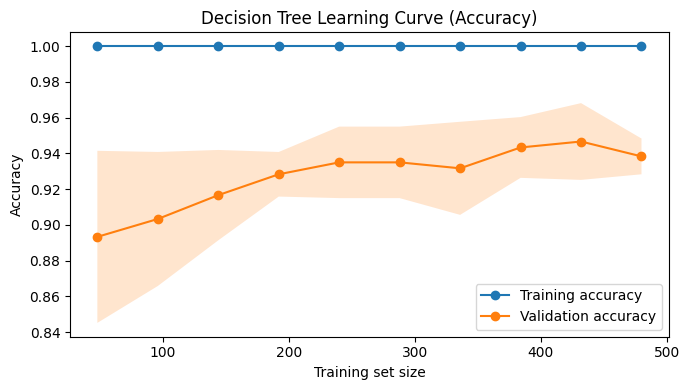

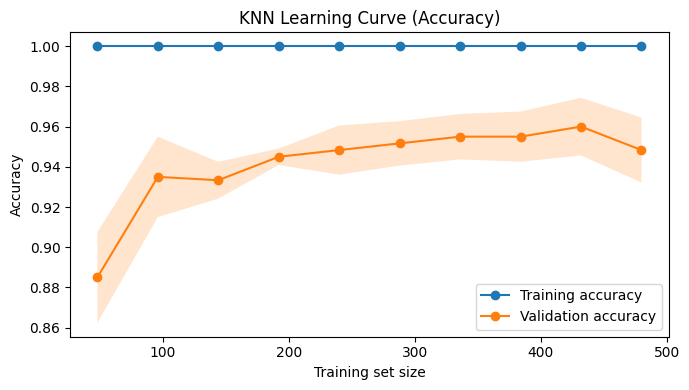

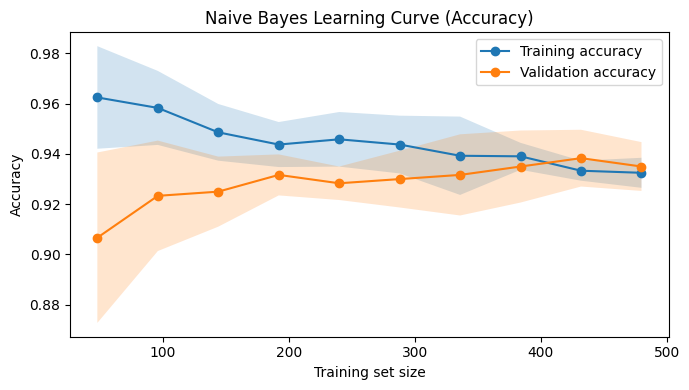

In [ ]:
# training vs validation accuracy vs training size (for all models)
def plot_learning_curve_accuracy(estimator, X, y, title, cv):
    train_sizes, train_scores, val_scores = learning_curve(
        estimator=estimator,
        X=X,
        y=y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=cv,
        scoring="accuracy",
        n_jobs=-1,
        shuffle=True,
        random_state=42
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    plt.figure(figsize=(7,4))
    plt.plot(train_sizes, train_mean, marker="o", label="Training accuracy")
    plt.plot(train_sizes, val_mean, marker="o", label="Validation accuracy")
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)
    plt.title(title)
    plt.xlabel("Training set size")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

for name, model in models:
    plot_learning_curve_accuracy(model, X_train_raw, y_train, f"{name} Learning Curve (Accuracy)", cv)

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, f1_score

def eval_on_test(model, X_train, y_train, X_test, y_test, model_name):
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    print(model_name)
    print("Accuracy: ", accuracy_score(y_test, preds))
    print("Precision: ", precision_score(y_test, preds, average="macro", zero_division=0))
    print("F-measure: ", f1_score(y_test, preds, average="macro"))
    print()

for name, model in models:
    eval_on_test(model, X_train_raw, y_train, X_test_raw, y_test, name)

Decision Tree
Accuracy:  0.9575
Precision:  0.9569413018003622
F-measure:  0.9573954599761052

KNN
Accuracy:  0.96
Precision:  0.9604466316642927
F-measure:  0.9599889735722344

Naive Bayes
Accuracy:  0.93
Precision:  0.9306551657297927
F-measure:  0.9272542055353591



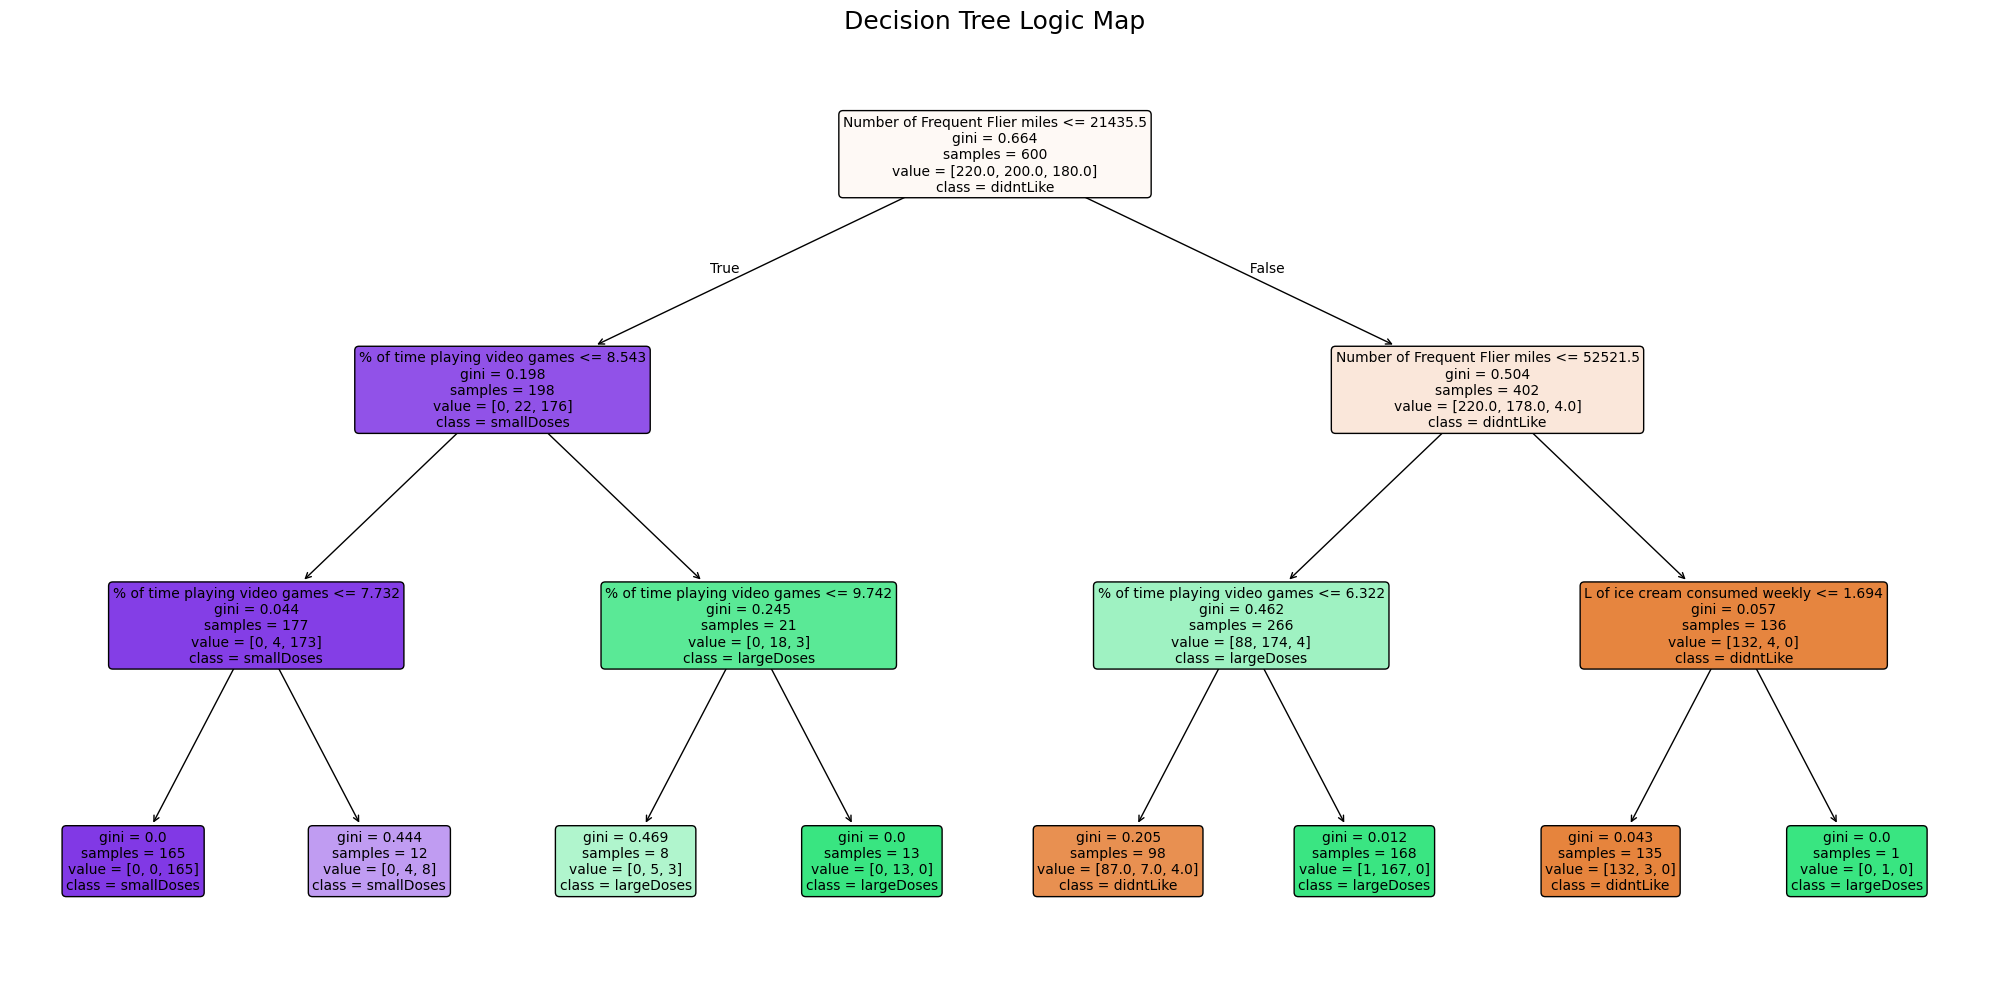

In [ ]:
## Visualizing the Decision Tree Flowchart
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

# Get the actual class names from the training target variable
actual_class_names = [str(c) for c in sorted(y_train.unique())]

# Plot the tree using Matplotlib
plot_tree(
    dt_interpretable,
    feature_names=feature_names_list,
    class_names=actual_class_names,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree Logic Map", fontsize=18)
plt.tight_layout()
plt.show()